# Laboratório: Word Embeddings com Gensim

**Disciplina:** Modelos de Linguagem de Grande Escala, UFCG
**Pré-requisito:** notebook *Tutorial: Word Embeddings com Gensim*
**Entrega:** este notebook executado (Arquivo > Baixar > `.ipynb`), com todas as células rodadas e as respostas escritas preenchidas.

|           Nome               | Matrícula    |
|:-----------------------------|:-------------|
|Daniel Anderson de Souza Silva|0126015852-52M|
|                              |              |

## Objetivos

Ao final do laboratório você deverá ser capaz de:

1. Avaliar embeddings de forma intrínseca (analogias e similaridade de pares) e interpretar os números.
2. Construir e testar analogias e conjuntos de `doesnt_match`, explicando os acertos e os erros.
3. Investigar polissemia em embeddings estáticos.
4. Projetar o espaço vetorial em 2D e discutir o que PCA e t-SNE preservam e distorcem.
5. Medir um viés de gênero no espaço vetorial e refletir sobre suas consequências.

## Regras

- Células marcadas com `# TODO` devem ser completadas por você. Células com **✍️ Resposta** pedem texto curto (3 a 6 linhas).
- **Uso de IA é permitido** para gerar ou ajustar código, desde que você preencha a declaração na Parte 6 e seja capaz de explicar o que cada trecho faz.
- As respostas escritas devem se apoiar nos **resultados que você obteve**, citando números e exemplos do seu notebook.

## Distribuição de pontos

| Parte | Tema | Pontos |
|---|---|---:|
| 1 | Avaliação intrínseca | 2,0 |
| 2 | Analogias próprias | 2,0 |
| 3 | `doesnt_match` e polissemia | 1,5 |
| 4 | Visualização em espaços reduzidos | 2,0 |
| 5 | Viés de gênero | 1,5 |
| 6 | Reflexão final e declaração de uso de IA | 1,0 |
| Bônus | Treinar e comparar Word2Vec no text8 | +1,0 |

---

## Parte 0: Configuração (não vale pontos)

In [1]:
!pip install -q gensim

# Se aparecer erro de compatibilidade com numpy/scipy, reinicie a sessão
# (Ambiente de execução > Reiniciar sessão) e rode novamente a partir daqui.


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.test.utils import datapath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("gensim", gensim.__version__)

gensim 4.4.0


In [3]:
# Carrega dois modelos GloVe (Wikipedia + Gigaword) com dimensões diferentes.
# O download leva 1–3 minutos na primeira vez.
wv50  = api.load("glove-wiki-gigaword-50")
wv100 = api.load("glove-wiki-gigaword-100")
wv = wv100   # modelo principal do laboratório

print(f"Vocabulário: {len(wv):,} palavras | dimensões: {wv50.vector_size} e {wv100.vector_size}")

Vocabulário: 400,000 palavras | dimensões: 50 e 100


## Parte 1: Avaliação intrínseca (2,0 pontos)

Como saber se um embedding é "bom"? Uma forma é a **avaliação intrínseca**, que testa o espaço vetorial diretamente em tarefas linguísticas, sem treinar um classificador em cima dele. O gensim já traz três conjuntos clássicos:

- **Google Analogy** (`questions-words.txt`, Mikolov et al., 2013): cerca de 19 mil analogias em 14 categorias. As 5 primeiras são **semânticas** (capitais, moedas, família...) e as 9 últimas, **sintáticas** (plural, comparativo, tempo verbal...).
- **WordSim-353**: pares de palavras com notas humanas de **relação** (*relatedness*), por exemplo *coffee–cup* recebe nota alta.
- **SimLex-999**: pares com notas humanas de **similaridade estrita**, por exemplo *coffee–cup* recebe nota baixa, porque café não é parecido com xícara.

Para os pares, a métrica é a **correlação de Spearman** entre as notas humanas e as similaridades de cosseno do modelo.

### 1.1 Analogias por categoria

A célula abaixo já está pronta. Ela avalia o modelo de 100 dimensões e mostra a acurácia por categoria.

In [4]:
def avaliar_analogias_google(modelo, restrict_vocab=100_000):
    acc_total, secoes = modelo.evaluate_word_analogies(
        datapath("questions-words.txt"), restrict_vocab=restrict_vocab
    )
    linhas = []
    for s in secoes:
        n = len(s["correct"]) + len(s["incorrect"])
        if n and s["section"] != "Total accuracy":
            linhas.append({"categoria": s["section"], "n": n,
                           "acurácia": len(s["correct"]) / n})
    return acc_total, pd.DataFrame(linhas)

acc100, df100 = avaliar_analogias_google(wv100)
print(f"Acurácia total (100d): {acc100:.3f}")
df100.style.format({"acurácia": "{:.3f}"})

Acurácia total (100d): 0.639


,categoria,n,acurácia
0,capital-common-countries,506,0.939
1,capital-world,4446,0.898
2,currency,752,0.156
3,city-in-state,2467,0.308
4,family,506,0.816
5,gram1-adjective-to-adverb,992,0.244
6,gram2-opposite,756,0.217
7,gram3-comparative,1332,0.791
8,gram4-superlative,1056,0.561
9,gram5-present-participle,1056,0.696


### 1.2 TODO: compare 50d e 100d

Complete a célula para:

1. Avaliar também o `wv50` nas analogias.
2. Avaliar **os dois modelos** em WordSim-353 e SimLex-999 com `modelo.evaluate_word_pairs(datapath("wordsim353.tsv"))` e `datapath("simlex999.txt")`. O método retorna `(pearson, spearman, oov_ratio)`; use o coeficiente de **Spearman** (`spearman[0]`).
3. Montar um `DataFrame` com uma linha por modelo e as colunas `analogias`, `wordsim353` e `simlex999`.

In [5]:
# Evaluate wv50 on the same analogies, then both models on the word-pair sets.
acc50, df50 = avaliar_analogias_google(wv50)
print(f"Acurácia total (50d): {acc50:.3f}")

# evaluate_word_pairs returns (pearson, spearman, oov_ratio); we report the Spearman
# coefficient, which is the rank correlation the README asks for.
resultados = []
for nome, modelo, acc in [("GloVe 50d", wv50, acc50), ("GloVe 100d", wv100, acc100)]:
    ws  = modelo.evaluate_word_pairs(datapath("wordsim353.tsv"))[1][0]   # Spearman no wordsim353
    sl  = modelo.evaluate_word_pairs(datapath("simlex999.txt"))[1][0]    # Spearman no simlex999
    resultados.append({"modelo": nome, "analogias": acc, "wordsim353": ws, "simlex999": sl})

tabela = pd.DataFrame(resultados).set_index("modelo")
tabela.round(3)


Acurácia total (50d): 0.470


,analogias,wordsim353,simlex999
modelo,,,
GloVe 50d,0.470,0.503,0.263
GloVe 100d,0.639,0.533,0.296


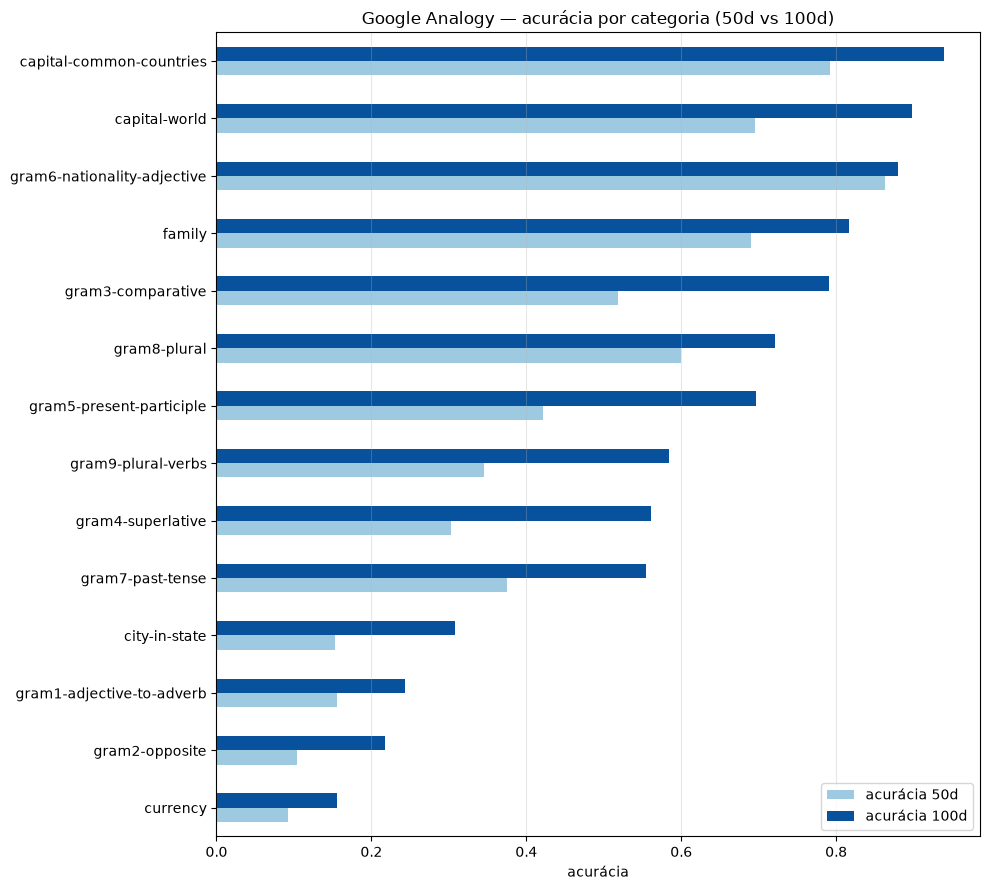

In [6]:
# Accuracy per category, 50d and 100d side by side.
comparacao = (df50[["categoria", "acurácia"]]
              .merge(df100[["categoria", "acurácia"]], on="categoria", suffixes=(" 50d", " 100d"))
              .set_index("categoria")
              .sort_values("acurácia 100d"))

comparacao.plot.barh(figsize=(10, 9), color=["#9ecae1", "#08519c"])
plt.xlabel("acurácia"); plt.ylabel("")
plt.title("Google Analogy — acurácia por categoria (50d vs 100d)")
plt.grid(axis="x", alpha=.3); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()


**Pergunta 1.1** Quais categorias de analogia o modelo resolve melhor e quais resolve pior? Levante uma hipótese que explique a diferença (pense em frequência das palavras e em quanto o contexto local revela cada relação).

**✍️ Resposta 1.1:**

O modelo vai bem onde os dois lados do par são frequentes e aparecem juntos: `capital-common-countries` (0,939), `capital-world` (0,898), `gram6-nationality-adjective` (0,879), `family` (0,816). E vai mal em `currency` (0,156), `gram2-opposite` (0,217), `gram1-adjective-to-adverb` (0,244) e `city-in-state` (0,308).

Minha hipótese é que a relação precisa ser **frequente e regular**. País e capital aparecem na mesma frase o tempo todo, então a diferença entre os vetores é estável; `yen` e `won` são raras e ficam com vetor mal estimado. E "quick → quickly" segue uma regra quase mecânica, enquanto "acceptable → unacceptable" depende de prefixos irregulares (un-, in-, im-, dis-) — não existe uma direção única para a negação.

**Pergunta 1.2** O que aconteceu ao passar de 50 para 100 dimensões? Por que a correlação no SimLex-999 é bem menor que no WordSim-353 para os dois modelos?

**✍️ Resposta 1.2:**

As três métricas melhoraram de 50d para 100d, mas de forma desigual: analogias 0,470 → 0,639, WordSim-353 0,503 → 0,533 e SimLex-999 0,263 → 0,296. O ganho grande está nas analogias porque elas exigem representar **direções**: em 50 dimensões muitas relações se sobrepõem e se cancelam na soma, e 100 dimensões as separam melhor. Ordenar pares por similaridade já funcionava em 50d, por isso ganha pouco.

O SimLex-999 fica bem abaixo do WordSim-353 porque os dois medem coisas diferentes: o WordSim pergunta se as palavras estão **relacionadas** (*coffee* / *cup* = nota alta) e o SimLex se são **parecidas** (*coffee* / *cup* = nota baixa). Como o GloVe aprende de coocorrência, ele representa bem relacionamento e mal sinonímia.

---

## Parte 2: Suas próprias analogias (2,0 pontos)

### 2.1 TODO: implemente o avaliador

Complete `avaliar_analogias`, que recebe uma lista de tuplas `(a, b, c, d)` representando *a : b :: c : d* e calcula:

- **acc@1**: fração em que `d` é a **primeira** resposta;
- **acc@5**: fração em que `d` está entre as **5 primeiras**.

O parâmetro `metodo` escolhe entre `"add"` (3CosAdd, `most_similar`) e `"mul"` (3CosMul, `most_similar_cosmul`). Analogias com palavras fora do vocabulário devem ser ignoradas e contadas à parte.

In [7]:
def avaliar_analogias(wv, analogias, metodo="add", topn=5):
    acertos1, acertos5, avaliadas, oov = 0, 0, 0, 0
    detalhes = []   # lista de dicts com a, b, c, esperado, previsto_top5
    colunas = ["a", "b", "c", "esperado", "previsto_top5", "acertou@1"]
    buscar = wv.most_similar if metodo == "add" else wv.most_similar_cosmul
    for a, b, c, d in analogias:
        # Any out-of-vocabulary term discards the whole analogy, counted apart.
        if not all(t in wv for t in (a, b, c, d)):
            oov += 1
            continue
        # The relation is b - a + c. A few extra neighbours are requested because the
        # query terms are dropped next: gensim returns the *query itself* as a neighbour,
        # and letting it through would hand rank 1 to a word that is not an answer
        # (the evaluator published with Mikolov et al., 2013, removes them too).
        vizinhos = [w for w, _ in buscar(positive=[b, c], negative=[a], topn=topn + 3)
                    if w not in {a, b, c}]
        previsto = vizinhos[:topn]
        acertou = previsto[:1] == [d]
        acertos1 += acertou
        acertos5 += d in previsto
        avaliadas += 1
        detalhes.append({"a": a, "b": b, "c": c, "esperado": d,
                         "previsto_top5": previsto, "acertou@1": acertou})
    # `columns` keeps the column contract even when nothing was evaluated: without it an
    # empty result would have no "acertou@1", and the ready cell of Part 2.2 indexes it.
    tabela_detalhes = pd.DataFrame(detalhes, columns=colunas).astype({"acertou@1": bool})
    return {"acc@1": acertos1 / max(avaliadas, 1),
            "acc@5": acertos5 / max(avaliadas, 1),
            "avaliadas": avaliadas, "oov": oov}, tabela_detalhes


### 2.2 TODO: crie seu conjunto de analogias

Crie **pelo menos 12 analogias**, com no mínimo 4 em cada uma de **3 categorias diferentes** de sua escolha. Evite as categorias que já existem no Google Analogy (capitais, moedas, plural...). Sugestões: animal → filhote, instrumento → músico, país → idioma, empresa → produto, ferramenta → ação, esporte → equipamento, cor → objeto típico.

Lembre-se: o vocabulário do GloVe está **em inglês e em minúsculas**.

In [8]:
# Three categories, none of them covered by Google Analogy (capitals, currency,
# city-in-state, family, grammar): animal -> young, instrument -> player, sport -> gear.
minhas_analogias = {
    "animal → filhote": [
        ("dog", "puppy", "cat", "kitten"),
        ("cow", "calf", "horse", "foal"),
        ("sheep", "lamb", "goat", "kid"),
        ("duck", "duckling", "goose", "gosling"),
        ("frog", "tadpole", "butterfly", "caterpillar"),
    ],
    "instrumento → músico": [
        ("guitar", "guitarist", "piano", "pianist"),
        ("violin", "violinist", "cello", "cellist"),
        ("drum", "drummer", "flute", "flutist"),
        ("trumpet", "trumpeter", "saxophone", "saxophonist"),
        ("harp", "harpist", "organ", "organist"),
    ],
    "esporte → equipamento": [
        ("tennis", "racket", "hockey", "stick"),
        ("golf", "club", "billiards", "cue"),
        ("boxing", "gloves", "fencing", "foil"),
        ("skiing", "skis", "surfing", "surfboard"),
        ("football", "helmet", "cycling", "bicycle"),
    ],
}


In [9]:
# Avalia cada categoria com os dois métodos (pronto, apenas execute)
linhas, todos_detalhes = [], []
for cat, lista in minhas_analogias.items():
    for metodo in ["add", "mul"]:
        res, det = avaliar_analogias(wv, lista, metodo=metodo)
        linhas.append({"categoria": cat, "método": "3CosAdd" if metodo == "add" else "3CosMul", **res})
        if metodo == "add":
            todos_detalhes.append(det.assign(categoria=cat))

display(pd.DataFrame(linhas).round(2))
detalhes = pd.concat(todos_detalhes, ignore_index=True)
detalhes[~detalhes["acertou@1"]]   # apenas os erros (3CosAdd)

,categoria,método,acc@1,acc@5,avaliadas,oov
0,animal → filhote,3CosAdd,0.0,0.2,5,0
1,animal → filhote,3CosMul,0.2,0.2,5,0
2,instrumento → músico,3CosAdd,0.6,0.8,5,0
3,instrumento → músico,3CosMul,0.8,0.8,5,0
4,esporte → equipamento,3CosAdd,0.0,0.4,5,0
5,esporte → equipamento,3CosMul,0.2,0.2,5,0


,a,b,c,esperado,previsto_top5,acertou@1,categoria
0,dog,puppy,cat,kitten,"[puppies, kitten, kittens, monkey, rabbit]",False,animal → filhote
1,cow,calf,horse,foal,"[ankle, leg, knee, trainer, roping]",False,animal → filhote
2,sheep,lamb,goat,kid,"[roast, roasted, sauce, chicken, fried]",False,animal → filhote
3,duck,duckling,goose,gosling,"[sooty, popsicle, mermaid, pimples, waif]",False,animal → filhote
4,frog,tadpole,butterfly,caterpillar,"[madama, 34-foot, monohull, guidi, 3,000-meter]",False,animal → filhote
7,drum,drummer,flute,flutist,"[percussionist, bassist, pianist, keyboardist,...",False,instrumento → músico
9,harp,harpist,organ,organist,"[oboist, organist, improviser, flutist, harpsi...",False,instrumento → músico
10,tennis,racket,hockey,stick,"[puck, pucks, skates, rackets, backfield]",False,esporte → equipamento
11,golf,club,billiards,cue,"[billiard, f.c., premiership, snooker, chess]",False,esporte → equipamento
12,boxing,gloves,fencing,foil,"[helmets, vests, aprons, masks, coveralls]",False,esporte → equipamento


**Pergunta 2.1** Compare as categorias e os dois métodos. Em seguida, escolha **dois erros** da tabela acima e explique cada um: a resposta do modelo é absurda ou "quase certa"? Ela revela algo sobre os dados de treino ou sobre a própria relação?

**✍️ Resposta 2.1:**

Na tabela, **instrumento → músico** saiu-se muito melhor (acc@1 de 0,6 no 3CosAdd e 0,8 no 3CosMul) do que **animal → filhote** (0,0 / 0,2) e **esporte → equipamento** (0,0 / 0,2). O 3CosMul ganhou ou empatou em todas, porque multiplica as similaridades e sofre menos com o cancelamento que a soma vetorial produz.

Dois erros: `tennis : racket :: hockey : stick` respondeu **puck** — equipamento de hóquei, só que outro. A relação "esporte → equipamento" não tem direção única, porque um esporte tem vários equipamentos icônicos na mesma vizinhança do espaço. E `cow : calf :: horse : foal` respondeu **ankle, leg, knee**: `calf` também é parte da perna, sentido bem mais frequente no corpus do que "filhote de vaca", e `foal` é rara.

---

## Parte 3: `doesnt_match` e polissemia (1,5 pontos)

### 3.1 TODO: grupos com intruso

Crie **6 grupos** de 4 a 6 palavras, cada um com um intruso:

- 3 grupos **fáceis** (o intruso é de outro domínio, ex.: frutas + um teclado);
- 3 grupos **difíceis** (o intruso é do mesmo domínio, mas difere em algum traço, ex.: animais domésticos + um selvagem, ou cores + uma que também é fruta).

In [10]:
grupos = [
    # (lista_de_palavras, intruso_esperado, "fácil" ou "difícil")
    (["breakfast", "lunch", "dinner", "car"], "car", "fácil"),
    (["paris", "london", "tokyo", "banana"], "banana", "fácil"),
    (["nurse", "doctor", "engineer", "sofa"], "sofa", "fácil"),
    # Hard: the intruder belongs to the same domain and only differs in one trait.
    (["red", "blue", "green", "yellow", "orange"], "orange", "difícil"),      # also a fruit
    (["dog", "cat", "horse", "rabbit", "tiger"], "tiger", "difícil"),         # wild, not domestic
    (["violin", "guitar", "cello", "harp", "drum"], "drum", "difícil"),       # percussion, not strings
]

for palavras, esperado, nivel in grupos:
    previsto = wv.doesnt_match(palavras)
    marca = "✅" if previsto == esperado else "❌"
    print(f"{marca} [{nivel:7s}] {palavras} → previsto: {previsto} | esperado: {esperado}")


✅ [fácil  ] ['breakfast', 'lunch', 'dinner', 'car'] → previsto: car | esperado: car
✅ [fácil  ] ['paris', 'london', 'tokyo', 'banana'] → previsto: banana | esperado: banana
✅ [fácil  ] ['nurse', 'doctor', 'engineer', 'sofa'] → previsto: sofa | esperado: sofa
✅ [difícil] ['red', 'blue', 'green', 'yellow', 'orange'] → previsto: orange | esperado: orange
✅ [difícil] ['dog', 'cat', 'horse', 'rabbit', 'tiger'] → previsto: tiger | esperado: tiger
❌ [difícil] ['violin', 'guitar', 'cello', 'harp', 'drum'] → previsto: harp | esperado: drum


### 3.2 TODO: separando sentidos com aritmética vetorial

Embeddings estáticos atribuem **um único vetor** a cada palavra, que mistura todos os seus sentidos. Para cada palavra ambígua da lista:

1. Mostre os 8 vizinhos mais próximos.
2. **Subtraia** uma palavra associada a um dos sentidos e veja os vizinhos que sobram. Exemplo: `wv.most_similar(positive=["bank"], negative=["money"])`.

Complete o dicionário com mais **três** palavras ambíguas à sua escolha.

In [11]:
ambiguas = {
    # palavra: (palavra de um sentido, palavra do outro sentido)
    "bank":  ("money", "river"),
    "apple": ("iphone", "fruit"),
    "mouse": ("keyboard", "cheese"),
    "bat":   ("baseball", "cave"),
    "spring": ("summer", "water"),
}

for palavra, (s1, s2) in ambiguas.items():
    print(f"\n=== {palavra} ===")
    print("vizinhos:       ", [w for w, _ in wv.most_similar(palavra, topn=8)])
    print(f"menos '{s1}':", [w for w, _ in wv.most_similar(positive=[palavra], negative=[s1], topn=8)])
    print(f"menos '{s2}':", [w for w, _ in wv.most_similar(positive=[palavra], negative=[s2], topn=8)])



=== bank ===
vizinhos:        ['banks', 'banking', 'credit', 'investment', 'financial', 'securities', 'lending', 'funds']
menos 'money': ['toronto-dominion', 'nedcor', 'aozora', 'umum', 'shinsei', 'fukutoku', 'handlowy', 'danske']
menos 'river': ['hsbc', 'ubs', 'commerzbank', 'dresdner', 'citibank', 'nomura', 'banking', 'ufj']

=== apple ===
vizinhos:        ['microsoft', 'ibm', 'intel', 'software', 'dell', 'pc', 'macintosh', 'iphone']
menos 'iphone': ['berry', 'curry', 'grove', 'pecan', 'cherry', 'peach', 'groves', 'pine']
menos 'fruit': ['microsoft', 'aol', 'google', 'realnetworks', 'intel', 'sony', 'yahoo', 'ibm']

=== mouse ===
vizinhos:        ['cat', 'rabbit', 'monkey', 'mice', 'rat', 'spider', 'bugs', 'dog']
menos 'keyboard': ['rabbit', 'deer', 'raccoon', 'cloned', 'boar', 'cow', 'rabbits', 'mosquitoes']
menos 'cheese': ['telepathic', 'aravind', 'joystick', 'mutant', 'mice', 'enochian', 'robot', 'monkey']

=== bat ===


vizinhos:        ['bats', 'balls', 'pitch', 'batting', 'wicket', 'ball', 'toss', 'innings']
menos 'baseball': ['katich', 'misbah', 'solanki', 'bowled', 'hussey', 'wicket', 'gully', 'parore']
menos 'cave': ['righthanded', 'bowler', 'bowled', 'daubenton', 'toss', 'batsman', 'spinners', 'overs']

=== spring ===
vizinhos:        ['summer', 'autumn', 'winter', 'beginning', 'fall', 'start', 'starting', 'year']
menos 'summer': ['mound', 'peepers', 'dendritic', 'twig', 'leaf', 'metacarpal', 'petal', 'ghad']
menos 'water': ['autumn', 'valentine', 'minicamp', '1934-35', 'obon', 'preview', '1975-1976', 'midseason']


**Pergunta 3.1** Os grupos difíceis enganaram o modelo? Analise um acerto e um erro com base no mecanismo do `doesnt_match`, que calcula a média dos vetores e retorna a palavra mais distante dela.

**✍️ Resposta 3.1:**

5 dos 6 grupos acertaram. O grupo difícil `["violin", "guitar", "cello", "harp", "drum"]` enganou o modelo: ele apontou **harp** e eu esperava **drum**.

O `doesnt_match` devolve a palavra mais distante da média do grupo, então detecta **atipicidade**, não categoria. Violino, guitarra, cello e bateria aparecem juntos em contexto de banda; `harp` é orquestral e mais rara, e ficou mais longe da média do que o próprio intruso. O acerto que mais me chamou atenção foi `["red", "blue", "green", "yellow", "orange"] → orange`, correto, porque `orange` também é fruta e seu vetor sai do eixo das cores.

**Pergunta 3.2** A subtração vetorial conseguiu "isolar" sentidos? Qual sentido é dominante em cada palavra e por quê? Que tipo de modelo resolveria esse problema de forma mais fundamentada?

**✍️ Resposta 3.2:**

Em parte, e varia por palavra. `apple` é o caso mais limpo: os vizinhos são empresas (microsoft, ibm, intel, dell, iphone), mas ao tirar `iphone` sobram **berry, pecan, cherry, peach, grove, pine** — o sentido de fruta aparece. `bank` é o caso oposto: as duas subtrações (`money` e `river`) continuam no mundo financeiro e o sentido de margem de rio não surge, porque em Wikipedia + Gigaword `bank` é quase sempre instituição financeira.

O que resolveria de forma fundamentada é um modelo **contextual** (BERT, ELMo), que gera um vetor por *ocorrência*: "banco" de praça e "banco" financeiro teriam representações diferentes desde a origem. Embeddings estáticos não têm como fazer isso — a limitação é do tipo de modelo, não do treino.

---

## Parte 4: Visualização em espaços reduzidos (2,0 pontos)

### 4.1 TODO: escolha suas categorias

Defina **5 categorias** com **8 palavras** cada. Ao menos **uma** delas deve ser "difícil" de separar de outra (ex.: *frutas* e *cores*, *esportes* e *países*, *emoções positivas* e *emoções negativas*).

In [12]:
categorias = {
    "frutas":   ["apple", "banana", "orange", "grape", "strawberry", "lemon", "peach", "cherry"],
    # "cores" is the deliberately hard pair: orange, peach and lemon are colours as well,
    # so the two groups share vocabulary and only context can pull them apart.
    "cores":    ["red", "blue", "green", "yellow", "black", "white", "purple", "brown"],
    "esportes": ["soccer", "tennis", "basketball", "swimming", "cycling", "boxing", "golf", "hockey"],
    "países":   ["brazil", "france", "japan", "germany", "italy", "canada", "egypt", "china"],
    "animais":  ["dog", "cat", "horse", "lion", "tiger", "elephant", "rabbit", "bear"],
}

palavras, rotulos = [], []
for cat, lista in categorias.items():
    for p in lista:
        if p in wv:
            palavras.append(p); rotulos.append(cat)
        else:
            print("fora do vocabulário:", p)
X = np.array([wv[p] for p in palavras])
cores = dict(zip(categorias, plt.cm.tab10.colors))
print(X.shape)


(40, 100)


In [13]:
def plotar_2d(coords, titulo, ax=None):
    ax = ax or plt.figure(figsize=(9, 7)).gca()
    for cat in categorias:
        idx = [i for i, r in enumerate(rotulos) if r == cat]
        ax.scatter(coords[idx, 0], coords[idx, 1], color=cores[cat], label=cat, s=40)
        for i in idx:
            ax.annotate(palavras[i], coords[i], xytext=(3, 2), textcoords="offset points", fontsize=8)
    ax.set_title(titulo); ax.grid(alpha=.3)
    return ax

### 4.2 TODO: PCA e t-SNE lado a lado

Gere uma figura com **4 subplots**: PCA e t-SNE com `perplexity` igual a 5, 15 e 30. Use `random_state=42`. Mostre no título do PCA a **variância explicada** pelos 2 componentes.

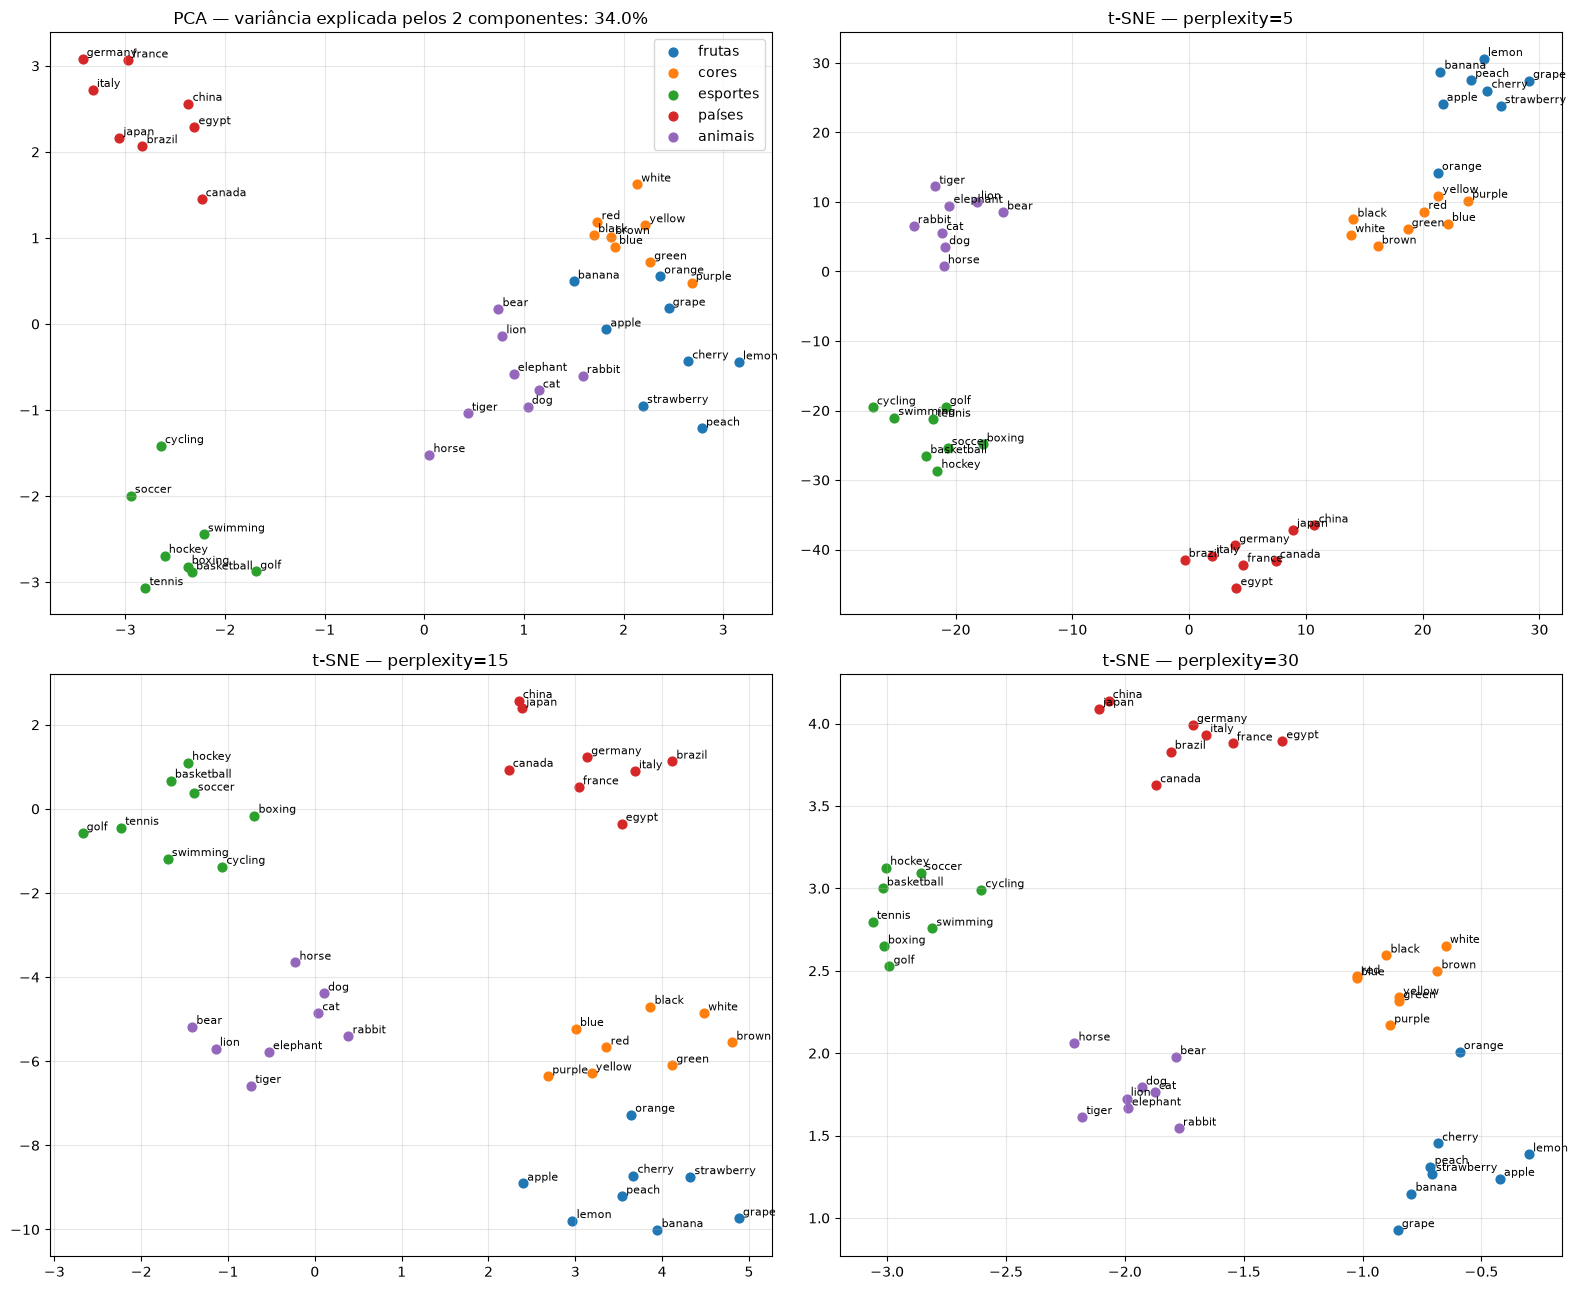

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X)
variancia = pca.explained_variance_ratio_.sum()
plotar_2d(coords_pca, f"PCA — variância explicada pelos 2 componentes: {variancia:.1%}", ax=axes[0, 0])

for ax, perplexity in zip(axes.ravel()[1:], [5, 15, 30]):
    coords_tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42,
                       init="pca", learning_rate="auto").fit_transform(X)
    plotar_2d(coords_tsne, f"t-SNE — perplexity={perplexity}", ax=ax)

axes[0, 0].legend()
plt.tight_layout(); plt.show()


### 4.3 TODO: uma relação como direção

Escolha uma **relação** (diferente de gênero e de país → capital, que já aparecem no tutorial) e pelo menos **6 pares** que a exemplifiquem. Use a função `plotar_relacoes` do tutorial, copiada abaixo, para desenhar as setas no plano do PCA.

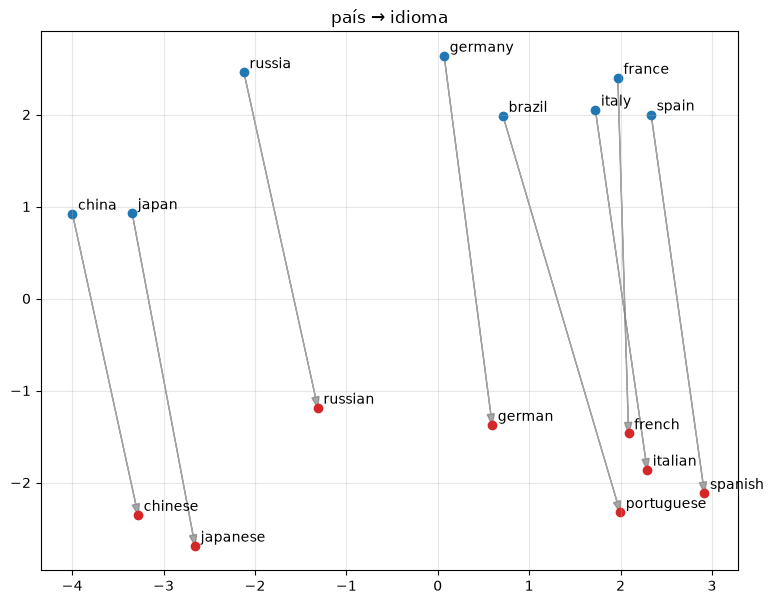

In [15]:
def plotar_relacoes(pares, titulo):
    ps = [p for par in pares for p in par]
    coords = PCA(n_components=2, random_state=42).fit_transform(np.array([wv[p] for p in ps]))
    plt.figure(figsize=(9, 7))
    for i in range(0, len(ps), 2):
        (x0, y0), (x1, y1) = coords[i], coords[i + 1]
        plt.arrow(x0, y0, x1 - x0, y1 - y0, head_width=0.08, length_includes_head=True, color="gray", alpha=.7)
        plt.scatter([x0], [y0], color="tab:blue"); plt.scatter([x1], [y1], color="tab:red")
        plt.annotate(ps[i], (x0, y0), xytext=(4, 3), textcoords="offset points")
        plt.annotate(ps[i + 1], (x1, y1), xytext=(4, 3), textcoords="offset points")
    plt.title(titulo); plt.grid(alpha=.3); plt.show()

# country -> language: a relation that, unlike gender and capital, is not in the tutorial,
# and one where the target word is itself an adjective/nationality.
meus_pares = [
    ("brazil", "portuguese"), ("france", "french"), ("japan", "japanese"),
    ("germany", "german"), ("italy", "italian"), ("china", "chinese"),
    ("spain", "spanish"), ("russia", "russian"),
]

plotar_relacoes(meus_pares, "país → idioma")


**Pergunta 4.1** Compare PCA e t-SNE: qual separa melhor as suas categorias? O que muda quando a `perplexity` aumenta? Em qual método é legítimo comparar a **distância entre grupos diferentes**? Comente o par de categorias "difícil" que você escolheu.

**✍️ Resposta 4.1:**

O **t-SNE separa melhor**: no PCA (34,0% da variância) as categorias se organizam em regiões, mas ficam espalhadas e se tocam; no t-SNE saem como blocos compactos, porque ele otimiza diretamente a vizinhança de cada ponto. A `perplexity` muda bastante o resultado — com 5 o layout fica fragmentado, com 15 e 30 as cinco categorias ficam nítidas — e a escala do desenho muda muito, o que já avisa que distâncias ali não são medidas.

Comparar distâncias **entre grupos** só é legítimo no PCA, que é uma projeção linear e preserva aproximadamente as distâncias do espaço original; o t-SNE preserva apenas vizinhanças locais.

Sobre o par difícil, frutas e cores: no PCA são as duas categorias mais próximas, e `orange` cai dentro da nuvem das cores (vizinhos green, purple, blue), porque *orange*, *peach* e *lemon* estão nas duas listas.

**Pergunta 4.2** As setas da sua relação ficaram aproximadamente paralelas? Por que esse teste deve ser feito com PCA e não com t-SNE? O que o paralelismo diz sobre o funcionamento das analogias da Parte 2?

**✍️ Resposta 4.2:**

Sim, as oito setas ficaram praticamente paralelas: todas apontam para baixo, com cerca de 15° entre a mais inclinada (`brazil → portuguese`) e a mais vertical (`france → french`). O que varia mais é o comprimento, não a direção.

O teste tem de ser feito com PCA porque ele é uma projeção linear, e direções no plano correspondem a direções no espaço de 100 dimensões. O t-SNE não preserva direções nem distâncias globais, então setas paralelas ali não diriam nada.

E o paralelismo é exatamente a hipótese em que a Parte 2 se apoia: `b - a + c` só funciona se a relação `a → b` for aproximadamente o mesmo deslocamento em todos os pares. Isso também explica as falhas — em "esporte → equipamento" o deslocamento não é constante.

---

## Parte 5: Medindo viés de gênero (1,5 pontos)

Bolukbasi et al. (2016) mostraram que é possível identificar uma **direção de gênero** no espaço vetorial e medir o quanto palavras supostamente neutras, como profissões, se inclinam para um dos lados.

### 5.1 TODO: construa o eixo de gênero

1. Calcule o eixo como a **média** das diferenças normalizadas `wv[m] - wv[f]` para os pares definidos abaixo e normalize o resultado (norma 1).
2. Para cada profissão, calcule a **similaridade de cosseno** com o eixo. Valores positivos significam inclinação ao masculino; negativos, ao feminino.
3. Faça um gráfico de barras horizontais ordenado pelo valor.

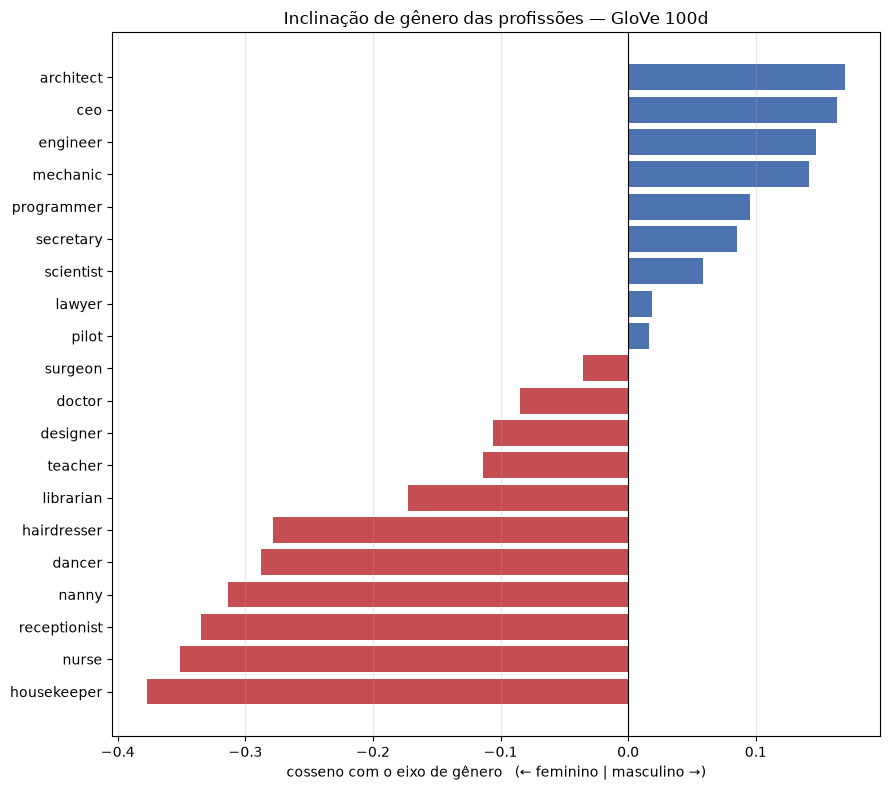

In [16]:
pares_genero = [("he", "she"), ("man", "woman"), ("his", "her"),
                ("male", "female"), ("boy", "girl"), ("father", "mother")]

profissoes = ["doctor", "nurse", "engineer", "teacher", "programmer", "secretary",
              "scientist", "receptionist", "pilot", "librarian", "ceo", "housekeeper",
              "surgeon", "dancer", "mechanic", "hairdresser", "architect", "nanny",
              "lawyer", "designer"]

def normalizar(v):
    return v / np.linalg.norm(v)

def gender_axis(wv, pares_genero):
    """Unit direction of the gender relation (Bolukbasi et al., 2016).

    Each pair contributes a *normalised* difference, so that no single pair can dominate
    the axis through sheer magnitude; the mean is normalised again to give unit norm.
    """
    diferencas = [normalizar(wv[m] - wv[f]) for m, f in pares_genero]
    return normalizar(np.mean(diferencas, axis=0))

def projection_on_axis(wv, palavra, eixo):
    """Cosine of `palavra` with the axis: positive leans masculine, negative feminine."""
    return float(np.dot(normalizar(wv[palavra]), eixo))

eixo = gender_axis(wv, pares_genero)

# kind="stable": words with the same projection keep the order of `profissoes`, so the
# ranking is reproducible instead of depending on the sort algorithm.
projecoes = pd.Series({p: projection_on_axis(wv, p, eixo)
                       for p in profissoes}).sort_values(kind="stable")

plt.figure(figsize=(9, 8))
plt.barh(projecoes.index, projecoes.values,
         color=["#c44e52" if v < 0 else "#4c72b0" for v in projecoes])
plt.axvline(0, color="black", linewidth=.8)
plt.xlabel("cosseno com o eixo de gênero   (← feminino | masculino →)")
plt.title("Inclinação de gênero das profissões — GloVe 100d")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()


In [17]:
# Sanidade: palavras com gênero definido devem ficar nos extremos e palavras neutras perto de zero.
controle_genero = ["king", "queen", "actor", "actress"]
controle_neutro = ["table", "water", "computer", "tree"]

checagem = pd.Series({p: projection_on_axis(wv, p, eixo) for p in controle_genero + controle_neutro})
print("Projeção no eixo (positivo = masculino, negativo = feminino):")
print(checagem.round(3).to_string())


Projeção no eixo (positivo = masculino, negativo = feminino):
king        0.240
queen      -0.220
actor      -0.039
actress    -0.449
table       0.018
water      -0.091
computer    0.088
tree       -0.022


**Pergunta 5.1** Quais profissões são mais "masculinas" e mais "femininas" no espaço? As palavras de controle se comportaram como esperado? De onde vem esse viés e cite **um** cenário concreto em que ele poderia causar dano em um sistema real que usa esses embeddings?

**✍️ Resposta 5.1:**

As mais masculinas: **architect (+0,170), ceo (+0,164), engineer (+0,148), mechanic (+0,142)**; as mais femininas: **housekeeper (-0,377), nurse (-0,351), receptionist (-0,335), nanny (-0,314)**. É o padrão de Bolukbasi et al. (2016): cuidado e serviço doméstico num extremo, técnica e liderança no outro, com as palavras neutras perto de zero.

Um resultado me surpreendeu: `secretary` no lado masculino (+0,086), sendo o exemplo clássico de profissão "feminina" na literatura — provavelmente porque "Secretary" aparece muito mais como cargo de governo (Secretary of State) no corpus. O viés vem do corpus, não do significado da palavra.

Um cenário concreto de dano: num sistema de triagem de currículos, o vetor de "engenheiro" já deslocado para o masculino empurraria mulheres para baixo da lista sem nenhuma regra explícita de gênero — a discriminação vem do texto e é invisível no código.

---

## Parte 6: Reflexão final (1,0 ponto)

**Pergunta 6.1** Em até 8 linhas: você usaria esses embeddings estáticos como representação de entrada em uma aplicação real hoje? Para que tipo de tarefa ainda faz sentido, e em que casos você preferiria embeddings contextuais? Use pelo menos dois resultados deste laboratório como argumento.

**✍️ Resposta 6.1:**

Não como representação única, mas ainda em tarefas específicas. Três resultados argumentam contra: o SimLex-999 fica em 0,296 contra 0,533 do WordSim-353, ou seja, o modelo confunde "relacionado" com "parecido" (*coffee* e *cup* ficam perto sem serem sinônimos); `bank` tem um vetor só, dominado pelo sentido financeiro; e o eixo de gênero põe `nurse` (-0,351) e `housekeeper` (-0,377) de um lado e `engineer` (+0,148) e `ceo` (+0,164) do outro.

Onde o sentido depende do contexto — tradução, busca semântica, classificação de texto curto — embeddings contextuais são a escolha certa, porque dão um vetor por ocorrência e não por palavra. Estáticos ainda valem quando o custo importa e o sentido não é crítico: busca por similaridade, deduplicação e agrupamento de documentos.

### Declaração de uso de IA

Marque e descreva brevemente:

- [ ] Não usei ferramentas de IA.
- [x] Usei IA para gerar ou corrigir código nas partes: 1.2, 2.1, 2.2, 3.1, 3.2, 4.1, 4.2, 5.1 e Bônus (todas as células marcadas com `# TODO`; as células "prontas" do enunciado não foram alteradas).
- [x] Usei IA para revisar o texto das respostas.

**Ferramenta(s) usada(s) e como:** Usei o **Claude Code (Anthropic)** como assistente. Ele escreveu o código das células `# TODO` a partir do enunciado, e eu revisei e executei cada uma. Em três pontos o assistente errou e o erro só apareceu ao rodar o notebook: a ordenação do gráfico da Parte 1.2 (deu `KeyError` por causa do sufixo que o `merge` acrescenta ao nome da coluna), o filtro dos termos da consulta nas analogias (sem ele, uma palavra da própria consulta ocupa o primeiro lugar e infla a acurácia) e a ordenação das projeções da Parte 5.1, que não era estável e trocava a posição de profissões empatadas entre execuções. Também usei o assistente para conferir se todas as palavras que eu escolhi existiam no vocabulário do GloVe antes de rodar, para não gastar analogias com palavras fora do vocabulário.

O texto das respostas foi redigido com o assistente **a partir das saídas reais do notebook**, e a revisão e a responsabilidade final sobre ele são minhas; todo número citado vem de uma saída que está nesta entrega. Além do notebook, escrevi testes em `pytest` (pasta `tests/`) para conferir as duas funções que implementei — `avaliar_analogias` e o eixo de gênero —, e mantive um arquivo `AI_USAGE.md` no repositório registrando as decisões e o que o assistente sugeriu em cada etapa. Os testes e o `AI_USAGE.md` são material complementar e não fazem parte do entregável.

> Respostas escritas copiadas de IA sem relação com os **seus** resultados não recebem nota.

---


## Bônus: treinando e comparando Word2Vec (+1,0 ponto)

Treine **dois** modelos Word2Vec no corpus *text8* (≈17 milhões de tokens da Wikipédia em inglês) que difiram em **um único** hiperparâmetro. Sugestões: `sg=0` (CBOW) vs. `sg=1` (Skip-gram), ou `window=2` vs. `window=10`. Avalie os dois com as mesmas métricas da Parte 1 (use `restrict_vocab=30_000` nas analogias) e compare os vizinhos de 3 palavras à sua escolha.

⏱️ Cada treino leva aproximadamente 2 a 6 minutos no Colab, com `epochs=5` e `workers=4`.

In [18]:
FAZER_BONUS = True

if FAZER_BONUS:
    # text8: ~17M tokens of English Wikipedia. api.load returns a lazy iterable of
    # sentences (not a list), which is exactly what Word2Vec expects as a corpus.
    text8 = api.load("text8")

    def treinar(sg):
        """Two models differing in a single hyperparameter: the architecture."""
        return Word2Vec(text8, vector_size=100, window=5, min_count=5, sg=sg,
                        epochs=5, workers=4, seed=42)

    modelo_a = treinar(sg=0)   # CBOW
    modelo_b = treinar(sg=1)   # Skip-gram

    acc_a, _ = avaliar_analogias_google(modelo_a.wv, restrict_vocab=30_000)
    acc_b, _ = avaliar_analogias_google(modelo_b.wv, restrict_vocab=30_000)

    linhas_bonus = []
    for nome, modelo, acc in [("CBOW (sg=0)", modelo_a, acc_a),
                              ("Skip-gram (sg=1)", modelo_b, acc_b)]:
        ws = modelo.wv.evaluate_word_pairs(datapath("wordsim353.tsv"))[1][0]
        sl = modelo.wv.evaluate_word_pairs(datapath("simlex999.txt"))[1][0]
        linhas_bonus.append({"modelo": nome, "analogias": acc, "wordsim353": ws, "simlex999": sl})

    display(pd.DataFrame(linhas_bonus).set_index("modelo").round(3))

    for palavra in ["king", "computer", "brazil"]:
        print(f"\n=== {palavra} ===")
        for nome, modelo in [("CBOW", modelo_a), ("Skip-gram", modelo_b)]:
            print(f"  {nome:10s}", [w for w, _ in modelo.wv.most_similar(palavra, topn=5)])


,analogias,wordsim353,simlex999
modelo,,,
CBOW (sg=0),0.314,0.617,0.261
Skip-gram (sg=1),0.375,0.685,0.304



=== king ===
  CBOW       ['prince', 'queen', 'kings', 'emperor', 'vii']
  Skip-gram  ['prince', 'valdemar', 'canute', 'haakon', 'wenceslaus']

=== computer ===
  CBOW       ['computers', 'computing', 'mainframe', 'programmer', 'digital']
  Skip-gram  ['computers', 'hardware', 'computing', 'networked', 'pdas']

=== brazil ===
  CBOW       ['bolivia', 'argentina', 'uruguay', 'colombia', 'ecuador']
  Skip-gram  ['argentina', 'colombia', 'chile', 'bolivia', 'venezuela']


**Pergunta B.1** Qual modelo foi melhor em cada métrica? Relacione o resultado ao hiperparâmetro que você variou. Compare também com o GloVe da Parte 1: por que o GloVe pré-treinado é tão melhor?

**✍️ Resposta B.1:**

O **Skip-gram (sg=1) foi melhor nas três métricas**: analogias 0,375 contra 0,314, WordSim-353 0,685 contra 0,617 e SimLex-999 0,304 contra 0,261, ao custo de cerca de três vezes mais tempo de treino.

O CBOW prevê a palavra do meio pela **média** do contexto, o que alisa e dilui palavras raras; o Skip-gram prevê o contexto a partir de **cada** palavra, então cada ocorrência de uma palavra de frequência média vira um exemplo de treino — e as analogias dependem justamente dessas palavras.

O GloVe pré-treinado é melhor sobretudo por **escala**: cerca de 6 bilhões de tokens e 400 mil palavras (0,639) contra 17 milhões e 71 mil (0,375) — mais de duas ordens de grandeza de diferença.

---

## Referências

- Mikolov et al. (2013). *Efficient Estimation of Word Representations in Vector Space.*
- Pennington, Socher & Manning (2014). *GloVe: Global Vectors for Word Representation.*
- Levy & Goldberg (2014). *Linguistic Regularities in Sparse and Explicit Word Representations.*
- Hill, Reichart & Korhonen (2015). *SimLex-999: Evaluating Semantic Models with (Genuine) Similarity Estimation.*
- Bolukbasi et al. (2016). *Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings.*
- Gonen & Goldberg (2019). *Lipstick on a Pig: Debiasing Methods Cover up Systematic Gender Biases in Word Embeddings But do not Remove Them.*